# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** [Tuliskan Nama Anda]  
**NIM:** [Tuliskan NIM Anda]  
**Username GitHub:** [Tuliskan Username GitHub Anda]  

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [1]:
from pathlib import Path
import polars as pl
import duckdb
import plotly.express as px
import plotly.graph_objects as go

# Lokasi dataset hasil cleaning
DATA_PATH = Path("../data/processed/flood_cleaned.parquet")

# Baca dataset dengan Polars LazyFrame
lf = pl.scan_parquet(DATA_PATH)

# Koneksi DuckDB
con = duckdb.connect()

# Buat view untuk analisis SQL
con.execute(f"""
    CREATE OR REPLACE VIEW flood AS
    SELECT *
    FROM read_parquet('{DATA_PATH.as_posix()}')
""")

print("Dataset siap untuk Exploratory Data Analysis")

Dataset siap untuk Exploratory Data Analysis


In [2]:
# Menghitung distribusi label banjir
flood_dist = (
    lf.group_by("flood_label")
    .agg(pl.len().alias("jumlah_data"))
    .sort("flood_label")
    .collect()
)

display(flood_dist)

flood_label,jumlah_data
f64,u32
0.0,1068121
1.0,84311


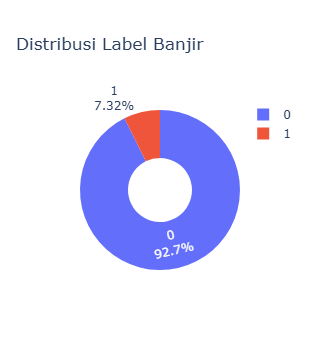

In [3]:
fig1 = px.pie(
    flood_dist.to_pandas(),
    names="flood_label",
    values="jumlah_data",
    title="Distribusi Label Banjir",
    hole=0.4,
    labels={
        "flood_label": "Status Banjir",
        "jumlah_data": "Jumlah Observasi"
    }
)

fig1.update_traces(
    textinfo="percent+label",
    hovertemplate="Status: %{label}<br>Jumlah: %{value:,}<br>Persentase: %{percent}<extra></extra>"
)

fig1.show()

In [4]:
yearly_flood = (
    lf.filter(pl.col("flood_label") == 1)
    .group_by("year")
    .agg(pl.len().alias("jumlah_banjir"))
    .sort("year")
    .collect()
)

display(yearly_flood)

year,jumlah_banjir
i64,u32
2015,6619
2016,15254
2017,7958
2018,4819
2019,5680
2020,13792
2021,13884
2022,4263
2023,4357


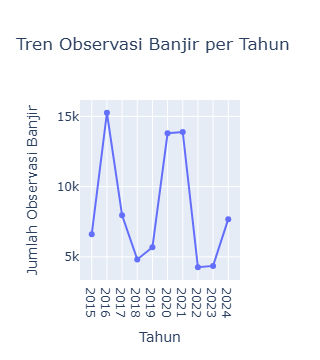

In [5]:
fig2 = px.line(
    yearly_flood.to_pandas(),
    x="year",
    y="jumlah_banjir",
    markers=True,
    title="Tren Observasi Banjir per Tahun",
    labels={
        "year": "Tahun",
        "jumlah_banjir": "Jumlah Observasi Banjir"
    }
)

fig2.update_traces(
    hovertemplate="Tahun: %{x}<br>Jumlah observasi: %{y:,}<extra></extra>"
)

fig2.update_layout(
    xaxis=dict(dtick=1),
    hovermode="x unified"
)

fig2.show()

In [6]:
rain_yearly = (
    lf.group_by("year")
    .agg([
        pl.col("rain_1d").mean().alias("rain_1d"),
        pl.col("rain_3d").mean().alias("rain_3d"),
        pl.col("rain_7d").mean().alias("rain_7d"),
        pl.col("rain_30d").mean().alias("rain_30d"),
    ])
    .sort("year")
    .collect()
)

display(rain_yearly)

year,rain_1d,rain_3d,rain_7d,rain_30d
i64,f64,f64,f64,f64
2015,5.65314,16.99629,39.680671,169.307264
2016,8.859358,26.534559,61.977852,269.556218
2017,5.999857,18.003554,42.013747,178.930131
2018,5.129479,15.441226,36.137918,153.078155
2019,5.858367,17.222283,39.602441,168.446925
2020,8.37433,25.401364,59.481177,255.021942
2021,8.100845,24.302959,56.699434,242.11906
2022,7.670289,22.939782,53.529772,231.170048
2023,5.248063,15.800511,37.058609,164.340552


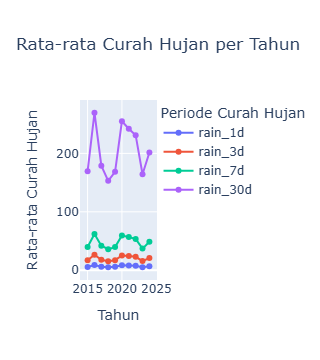

In [7]:
rain_plot = rain_yearly.to_pandas().melt(
    id_vars="year",
    var_name="Periode Curah Hujan",
    value_name="Rata-rata Curah Hujan"
)

fig3 = px.line(
    rain_plot,
    x="year",
    y="Rata-rata Curah Hujan",
    color="Periode Curah Hujan",
    markers=True,
    title="Rata-rata Curah Hujan per Tahun",
    labels={
        "year": "Tahun",
        "Rata-rata Curah Hujan": "Rata-rata Curah Hujan"
    }
)

fig3.update_layout(hovermode="x unified")
fig3.show()

In [8]:
rain_flood = (
    lf.group_by("flood_label")
    .agg([
        pl.col("rain_1d").mean().alias("rain_1d"),
        pl.col("rain_3d").mean().alias("rain_3d"),
        pl.col("rain_7d").mean().alias("rain_7d"),
        pl.col("rain_30d").mean().alias("rain_30d"),
    ])
    .sort("flood_label")
    .collect()
)

display(rain_flood)

flood_label,rain_1d,rain_3d,rain_7d,rain_30d
f64,f64,f64,f64,f64
0.0,5.983543,18.130548,42.801255,188.189397
1.0,17.060132,48.906222,107.86247,399.429276


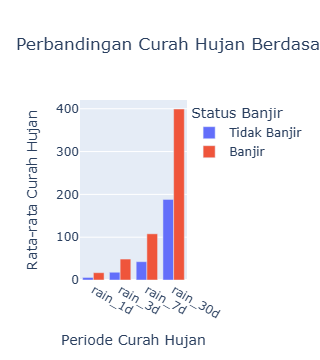

In [9]:
rain_flood_plot = rain_flood.to_pandas().melt(
    id_vars="flood_label",
    var_name="Periode Curah Hujan",
    value_name="Rata-rata Curah Hujan"
)

rain_flood_plot["Status Banjir"] = rain_flood_plot["flood_label"].map({
    0.0: "Tidak Banjir",
    1.0: "Banjir"
})

fig4 = px.bar(
    rain_flood_plot,
    x="Periode Curah Hujan",
    y="Rata-rata Curah Hujan",
    color="Status Banjir",
    barmode="group",
    title="Perbandingan Curah Hujan Berdasarkan Status Banjir",
    labels={
        "Periode Curah Hujan": "Periode Curah Hujan",
        "Rata-rata Curah Hujan": "Rata-rata Curah Hujan"
    }
)

fig4.show()

In [10]:
top_districts = (
    lf.filter(pl.col("flood_label") == 1)
    .group_by("district_id")
    .agg(
        pl.len().alias("jumlah_banjir")
    )
    .sort("jumlah_banjir", descending=True)
    .head(10)
    .collect()
)

display(top_districts)

district_id,jumlah_banjir
str,u32
"""IDN.7.5.7_1""",374
"""IDN.7.5.2_1""",362
"""IDN.10.17.6_1""",356
"""IDN.10.22.16_1""",349
"""IDN.10.22.17_1""",349
"""IDN.7.5.3_1""",344
"""IDN.10.16.1_1""",340
"""IDN.10.16.3_1""",340
"""IDN.10.16.4_1""",340


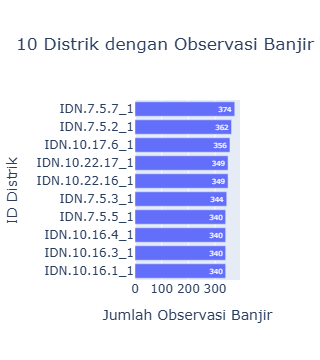

In [11]:
fig5 = px.bar(
    top_districts.to_pandas(),
    x="jumlah_banjir",
    y="district_id",
    orientation="h",
    text="jumlah_banjir",
    title="10 Distrik dengan Observasi Banjir Terbanyak",
    labels={
        "district_id": "ID Distrik",
        "jumlah_banjir": "Jumlah Observasi Banjir"
    }
)

fig5.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig5.show()

In [12]:
district_rate = (
    lf.group_by("district_id")
    .agg([
        pl.len().alias("total_observasi"),
        (pl.col("flood_label") == 1).sum().alias("jumlah_banjir")
    ])
    .with_columns(
        (
            pl.col("jumlah_banjir") /
            pl.col("total_observasi") * 100
        ).alias("persentase_banjir")
    )
    .sort("persentase_banjir", descending=True)
    .head(10)
    .collect()
)

display(district_rate)

district_id,total_observasi,jumlah_banjir,persentase_banjir
str,u32,u32,f64
"""IDN.7.5.7_1""",3624,374,10.320088
"""IDN.7.5.2_1""",3624,362,9.988962
"""IDN.10.17.6_1""",3624,356,9.8234
"""IDN.10.22.16_1""",3624,349,9.630243
"""IDN.10.22.17_1""",3624,349,9.630243
"""IDN.7.5.3_1""",3624,344,9.492274
"""IDN.10.16.1_1""",3624,340,9.381898
"""IDN.10.16.3_1""",3624,340,9.381898
"""IDN.10.16.4_1""",3624,340,9.381898


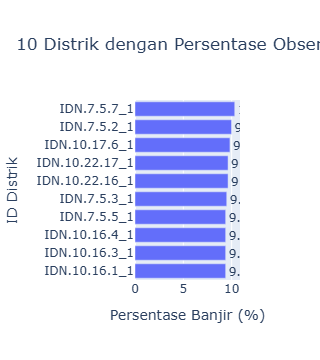

In [13]:
fig6 = px.bar(
    district_rate.to_pandas(),
    x="persentase_banjir",
    y="district_id",
    orientation="h",
    text="persentase_banjir",
    title="10 Distrik dengan Persentase Observasi Banjir Tertinggi",
    labels={
        "district_id": "ID Distrik",
        "persentase_banjir": "Persentase Banjir (%)"
    },
    hover_data=["jumlah_banjir", "total_observasi"]
)

fig6.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig6.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig6.show()

In [14]:
from pathlib import Path

FIG_DIR = Path("../output/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

figures = {
    "01_distribusi_label_banjir": fig1,
    "02_tren_banjir_tahunan": fig2,
    "03_curah_hujan_tahunan": fig3,
    "04_curah_hujan_status_banjir": fig4,
    "05_top10_distrik_banjir": fig5,
    "06_persentase_banjir_distrik": fig6,
}

for filename, fig in figures.items():
    fig.write_html(
        FIG_DIR / f"{filename}.html",
        include_plotlyjs=True
    )
    print("Tersimpan:", filename + ".html")

Tersimpan: 01_distribusi_label_banjir.html
Tersimpan: 02_tren_banjir_tahunan.html
Tersimpan: 03_curah_hujan_tahunan.html
Tersimpan: 04_curah_hujan_status_banjir.html
Tersimpan: 05_top10_distrik_banjir.html
Tersimpan: 06_persentase_banjir_distrik.html


In [15]:
from pathlib import Path

FIG_DIR = Path("../output/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

figures = {
    "01_distribusi_label_banjir": fig1,
    "02_tren_banjir_tahunan": fig2,
    "03_curah_hujan_tahunan": fig3,
    "04_curah_hujan_status_banjir": fig4,
    "05_top10_distrik_banjir": fig5,
    "06_persentase_banjir_distrik": fig6,
}

for filename, fig in figures.items():
    fig.write_html(
        FIG_DIR / f"{filename}.html",
        include_plotlyjs=True
    )
    print("Tersimpan:", filename + ".html")

Tersimpan: 01_distribusi_label_banjir.html
Tersimpan: 02_tren_banjir_tahunan.html
Tersimpan: 03_curah_hujan_tahunan.html
Tersimpan: 04_curah_hujan_status_banjir.html
Tersimpan: 05_top10_distrik_banjir.html
Tersimpan: 06_persentase_banjir_distrik.html


In [16]:
for file in sorted(FIG_DIR.glob("*.html")):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

print("Total grafik:", len(list(FIG_DIR.glob("*.html"))))

01_distribusi_label_banjir.html - 4710.59 KB
02_tren_banjir_tahunan.html - 4710.85 KB
03_curah_hujan_tahunan.html - 4712.67 KB
04_curah_hujan_status_banjir.html - 4711.49 KB
05_top10_distrik_banjir.html - 4711.11 KB
06_persentase_banjir_distrik.html - 4711.46 KB
Total grafik: 6


In [ ]:
# Hasil dan Insight Analisis Dataset Banjir

### Insight 1 – Ketidakseimbangan Label Banjir

Dataset memiliki 1.152.432 observasi. Sebanyak 1.068.121 observasi (92,68%) berlabel tidak banjir, sedangkan 84.311 observasi (7,32%) berlabel banjir. Distribusi ini menunjukkan adanya ketidakseimbangan kelas (*class imbalance*) yang perlu diperhatikan apabila dataset digunakan untuk pemodelan prediksi.

### Insight 2 – Fluktuasi Observasi Banjir Tahunan

Jumlah observasi berlabel banjir tertinggi terjadi pada tahun 2016 sebanyak 15.254 observasi, sedangkan jumlah terendah terjadi pada tahun 2022 sebanyak 4.263 observasi. Jumlah observasi berfluktuasi selama periode 2015–2024 dan tidak menunjukkan pola kenaikan yang konsisten.

### Insight 3 – Variasi Curah Hujan Tahunan

Rata-rata curah hujan tertinggi pada seluruh periode pengamatan terjadi pada tahun 2016, sedangkan rata-rata terendah terjadi pada tahun 2018. Pada tahun 2020 dan 2021, rata-rata curah hujan juga relatif tinggi. Hal ini memperlihatkan variasi kondisi curah hujan antar-tahun pada wilayah penelitian.

### Insight 4 – Hubungan Curah Hujan dengan Label Banjir

Observasi berlabel banjir memiliki rata-rata curah hujan lebih tinggi dibandingkan observasi tidak banjir pada seluruh periode yang dianalisis. Rata-rata curah hujan satu hari pada observasi banjir adalah 17,06, sedangkan pada observasi tidak banjir sebesar 5,98. Temuan ini menunjukkan adanya hubungan antara curah hujan dan label banjir, tetapi tidak membuktikan hubungan sebab-akibat.

### Insight 5 – Variasi Observasi Banjir Antarwilayah

Distrik IDN.7.5.7_1 memiliki jumlah observasi banjir terbanyak, yaitu 374 observasi. Setelah dibandingkan berdasarkan persentase, distrik tersebut juga memiliki proporsi observasi banjir tertinggi di antara 10 distrik teratas, yaitu sekitar 10,32%. Perbandingan ini menggunakan distrik dengan jumlah pengamatan yang sama, yaitu 3.624 observasi per distrik.

### Kesimpulan

Analisis menunjukkan bahwa label banjir dalam dataset memiliki distribusi tidak seimbang, jumlah observasi banjir berfluktuasi antar-tahun, dan rata-rata curah hujan pada observasi banjir lebih tinggi dibandingkan observasi tidak banjir. Selain itu, terdapat variasi proporsi observasi banjir antarwilayah.

Hasil ini merupakan temuan deskriptif dari dataset wilayah Pantura yang dianalisis dan tidak dapat langsung digeneralisasikan sebagai gambaran seluruh Indonesia.